In [1]:
# ============ Shared configuration ============
import numpy as np
import time

p, rr, risk = 0.4054, 1.92, 0.02
initial, T  = 10_000, 8
threshold   = 0.05
z           = 2.5758293035489004

def calculate_max_dd(wins):
    rets   = np.where(wins, risk * rr, -risk)
    equity = initial * np.cumprod(1 + rets, axis=1)
    peaks  = np.maximum.accumulate(
        np.column_stack([np.full(len(wins), initial), equity]), axis=1
    )[:, 1:]
    return (1 - equity / peaks).max(axis=1)

def has_3_losses(wins):
    """True if path contains 3 consecutive losses."""
    is_loss = ~wins
    out = np.zeros(wins.shape[0], dtype=bool)
    for i in range(T - 2):
        out |= (is_loss[:, i] & is_loss[:, i+1] & is_loss[:, i+2])
    return out

# ============ Classical Monte Carlo ============
N_mc = 200_000
rng  = np.random.default_rng(42)
wins_mc = rng.random((N_mc, T)) < p

hit_maxdd_mc = calculate_max_dd(wins_mc) > threshold
hit_3loss_mc = has_3_losses(wins_mc)

p_maxdd_mc = hit_maxdd_mc.mean()
p_3loss_mc = hit_3loss_mc.mean()

print("=" * 60)
print(f"Classical Monte Carlo (T={T}, threshold={threshold:.0%})")
print("=" * 60)
print(f"Paths                    : {N_mc:,}")
print(f"P(max DD > {threshold:.0%})         = {p_maxdd_mc:.4%}")
print(f"P(3 consecutive losses)  = {p_3loss_mc:.4%}")

# ============ Exact enumeration (2^8 = 256) ============
states      = ((np.arange(2**T)[:, None] >> np.arange(T)) & 1).astype(bool)
state_probs = np.prod(np.where(states, p, 1 - p), axis=1)

exact_dd    = calculate_max_dd(states)
exact_3loss = has_3_losses(states)

p_maxdd_exact = (state_probs * (exact_dd > threshold)).sum()
p_3loss_exact = (state_probs * exact_3loss).sum()

print("\n" + "=" * 60)
print("Exact enumeration")
print("=" * 60)
print(f"Total paths              : {2**T}")
print(f"Paths with maxDD>{threshold:.0%}   : {int((exact_dd > threshold).sum())}")
print(f"Paths with 3+ losses     : {int(exact_3loss.sum())}")
print(f"P(max DD > {threshold:.0%})         = {p_maxdd_exact:.6%}")
print(f"P(3 consecutive losses)  = {p_3loss_exact:.6%}")
print(f"Equivalence check (diff) : {abs(p_maxdd_exact - p_3loss_exact):.2e}")

# ============ Real quantum oracle: 3 consecutive losses ============
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

def build_oracle_3loss(T):
    """
    Phase oracle: -1 on basis states with 3+ consecutive 0s (losses).
    Real quantum circuit: computes the condition, applies phase, uncomputes.
    Ancillas returned to |0>.
    Qubits: 0..T-1 = W; T..T+n_trip-1 = triplet ancillas; T+n_trip = flag.
    """
    n_trip  = T - 2
    n_total = T + n_trip + 1
    qc = QuantumCircuit(n_total)

    W    = list(range(T))
    q    = list(range(T, T + n_trip))
    flag = T + n_trip

    # Step 1: q[i] = (W[i]=0) AND (W[i+1]=0) AND (W[i+2]=0)
    for i in range(n_trip):
        qc.x(W[i]); qc.x(W[i+1]); qc.x(W[i+2])
        qc.mcx([W[i], W[i+1], W[i+2]], q[i])
        qc.x(W[i]); qc.x(W[i+1]); qc.x(W[i+2])

    # Step 2: flag = AND(~q[i]) = "no 3-loss run anywhere"
    for i in range(n_trip):
        qc.x(q[i])
    qc.mcx(q, flag)
    for i in range(n_trip):
        qc.x(q[i])

    # Step 3: phase -1 iff flag=0 (i.e., has 3-loss run)
    qc.x(flag); qc.z(flag); qc.x(flag)

    # Step 4: uncompute flag
    for i in range(n_trip):
        qc.x(q[i])
    qc.mcx(q, flag)
    for i in range(n_trip):
        qc.x(q[i])

    # Step 5: uncompute q[i]
    for i in range(n_trip):
        qc.x(W[i]); qc.x(W[i+1]); qc.x(W[i+2])
        qc.mcx([W[i], W[i+1], W[i+2]], q[i])
        qc.x(W[i]); qc.x(W[i+1]); qc.x(W[i+2])

    return qc

# ============ Build Grover circuits ============
n_trip = T - 2
n_anc  = n_trip + 1
N_q    = T + n_anc

SHOTS    = 4000
k_values = np.array([0, 1, 2, 4])
rotation = 2 * np.arcsin(np.sqrt(p))

oracle = build_oracle_3loss(T)

circuits = []
for k in k_values:
    qc = QuantumCircuit(N_q)
    for i in range(T):
        qc.ry(rotation, i)
    for _ in range(int(k)):
        qc.compose(oracle, range(N_q), inplace=True)
        for i in range(T):
            qc.ry(-rotation, i)
        for i in range(T):
            qc.x(i)
        qc.mcp(np.pi, list(range(T - 1)), T - 1)
        for i in range(T):
            qc.x(i)
        for i in range(T):
            qc.ry(rotation, i)
    qc.measure_all()
    circuits.append(qc)

print("\n" + "=" * 60)
print("Quantum QAE (real oracle, no classical table)")
print("=" * 60)
print(f"Total qubits : {N_q}  ({T} path + {n_trip} triplet + 1 flag)")

simulator = AerSimulator(method="statevector")

print("Transpiling...")
t0 = time.time()
circuits_t = transpile(circuits, backend=simulator,
                       optimization_level=2, seed_transpiler=2026)
print(f"  done in {time.time()-t0:.1f}s")

print("Running...")
t0 = time.time()
result = simulator.run(circuits_t, shots=SHOTS, seed_simulator=2026).result()
print(f"  done in {time.time()-t0:.1f}s")

def count_3loss(counts_dict):
    total = 0
    for bs, cnt in counts_dict.items():
        w_bits = bs[::-1][:T]   # W[0]..W[T-1] in order
        w = [c == '1' for c in w_bits]
        if any((not w[i]) and (not w[i+1]) and (not w[i+2])
               for i in range(T - 2)):
            total += cnt
    return total

bad_counts = np.array([count_3loss(result.get_counts(i))
                       for i in range(len(k_values))])

print(f"k values         : {k_values}")
print(f"Bad-state counts : {bad_counts}")
print(f"Shots            : {SHOTS}")

# ============ MLE ============
from scipy.optimize import minimize_scalar

def log_likelihood(theta):
    probs = np.sin((2 * k_values + 1) * theta) ** 2
    probs = np.clip(probs, 1e-12, 1 - 1e-12)
    return np.sum(bad_counts * np.log(probs)
                  + (SHOTS - bad_counts) * np.log1p(-probs))

theta_grid = np.linspace(1e-7, np.pi / 2 - 1e-7, 200_001)
ll         = np.array([log_likelihood(th) for th in theta_grid])
best       = int(np.argmax(ll))
left       = theta_grid[max(0, best - 1)]
right      = theta_grid[min(len(theta_grid) - 1, best + 1)]

if right > left:
    fit = minimize_scalar(lambda th: -log_likelihood(th),
                          bounds=(left, right), method="bounded",
                          options={"xatol": 1e-12})
    theta_hat = fit.x
else:
    theta_hat = theta_grid[best]

quantum_prob = float(np.sin(theta_hat) ** 2)

# ============ Final comparison ============
print("\n" + "=" * 60)
print("FINAL COMPARISON")
print("=" * 60)
print(f"Exact     P(max DD > {threshold:.0%})     : {p_maxdd_exact:.6%}")
print(f"Exact     P(3 consecutive losses)  : {p_3loss_exact:.6%}")
print(f"Class.MC  P(max DD > {threshold:.0%})     : {p_maxdd_mc:.6%}")
print(f"Class.MC  P(3 consecutive losses)  : {p_3loss_mc:.6%}")
print(f"Quantum   QAE estimate             : {quantum_prob:.6%}")
print()
print(f"|Quantum - Exact(maxDD)|  : {abs(quantum_prob - p_maxdd_exact):.6%}")
print(f"|Quantum - Exact(3loss)|  : {abs(quantum_prob - p_3loss_exact):.6%}")

Classical Monte Carlo (T=8, threshold=5%)
Paths                    : 200,000
P(max DD > 5%)         = 59.3095%
P(3 consecutive losses)  = 59.3095%

Exact enumeration
Total paths              : 256
Paths with maxDD>5%   : 107
Paths with 3+ losses     : 107
P(max DD > 5%)         = 59.324258%
P(3 consecutive losses)  = 59.324258%
Equivalence check (diff) : 0.00e+00

Quantum QAE (real oracle, no classical table)
Total qubits : 15  (8 path + 6 triplet + 1 flag)
Transpiling...
  done in 0.3s
Running...
  done in 0.1s
k values         : [0 1 2 4]
Bad-state counts : [2400  921 3614 3991]
Shots            : 4000

FINAL COMPARISON
Exact     P(max DD > 5%)     : 59.324258%
Exact     P(3 consecutive losses)  : 59.324258%
Class.MC  P(max DD > 5%)     : 59.309500%
Class.MC  P(3 consecutive losses)  : 59.309500%
Quantum   QAE estimate             : 59.257322%

|Quantum - Exact(maxDD)|  : 0.066936%
|Quantum - Exact(3loss)|  : 0.066936%


In [2]:
print(
    "Pathwise equivalence:",
    np.array_equal(exact_dd > threshold, exact_3loss)
)

Pathwise equivalence: True


Trade |       Best |       Mean |    Mean-5% |      Worst
--------------------------------------------------------------
    0 |     10,000 |     10,000 |      9,500 |     10,000
    1 |     10,384 |     10,037 |      9,535 |      9,800
    2 |     10,783 |     10,072 |      9,569 |      9,604
    3 |     11,197 |     10,110 |      9,604 |      9,412
    4 |     11,627 |     10,148 |      9,640 |      9,224
    5 |     12,073 |     10,185 |      9,676 |      9,039
    6 |     12,537 |     10,223 |      9,712 |      8,858
    7 |     13,018 |     10,261 |      9,748 |      8,681
    8 |     13,518 |     10,298 |      9,783 |      8,508

--- خلاصه بعد از 8 معامله ---
احتمال سوددهی        : 69.51%
میانه مانده نهایی    : 10,121 $
میانگین مانده نهایی  : 10,298 $
بهترین سناریو        : 13,518 $
بدترین سناریو        : 8,508 $


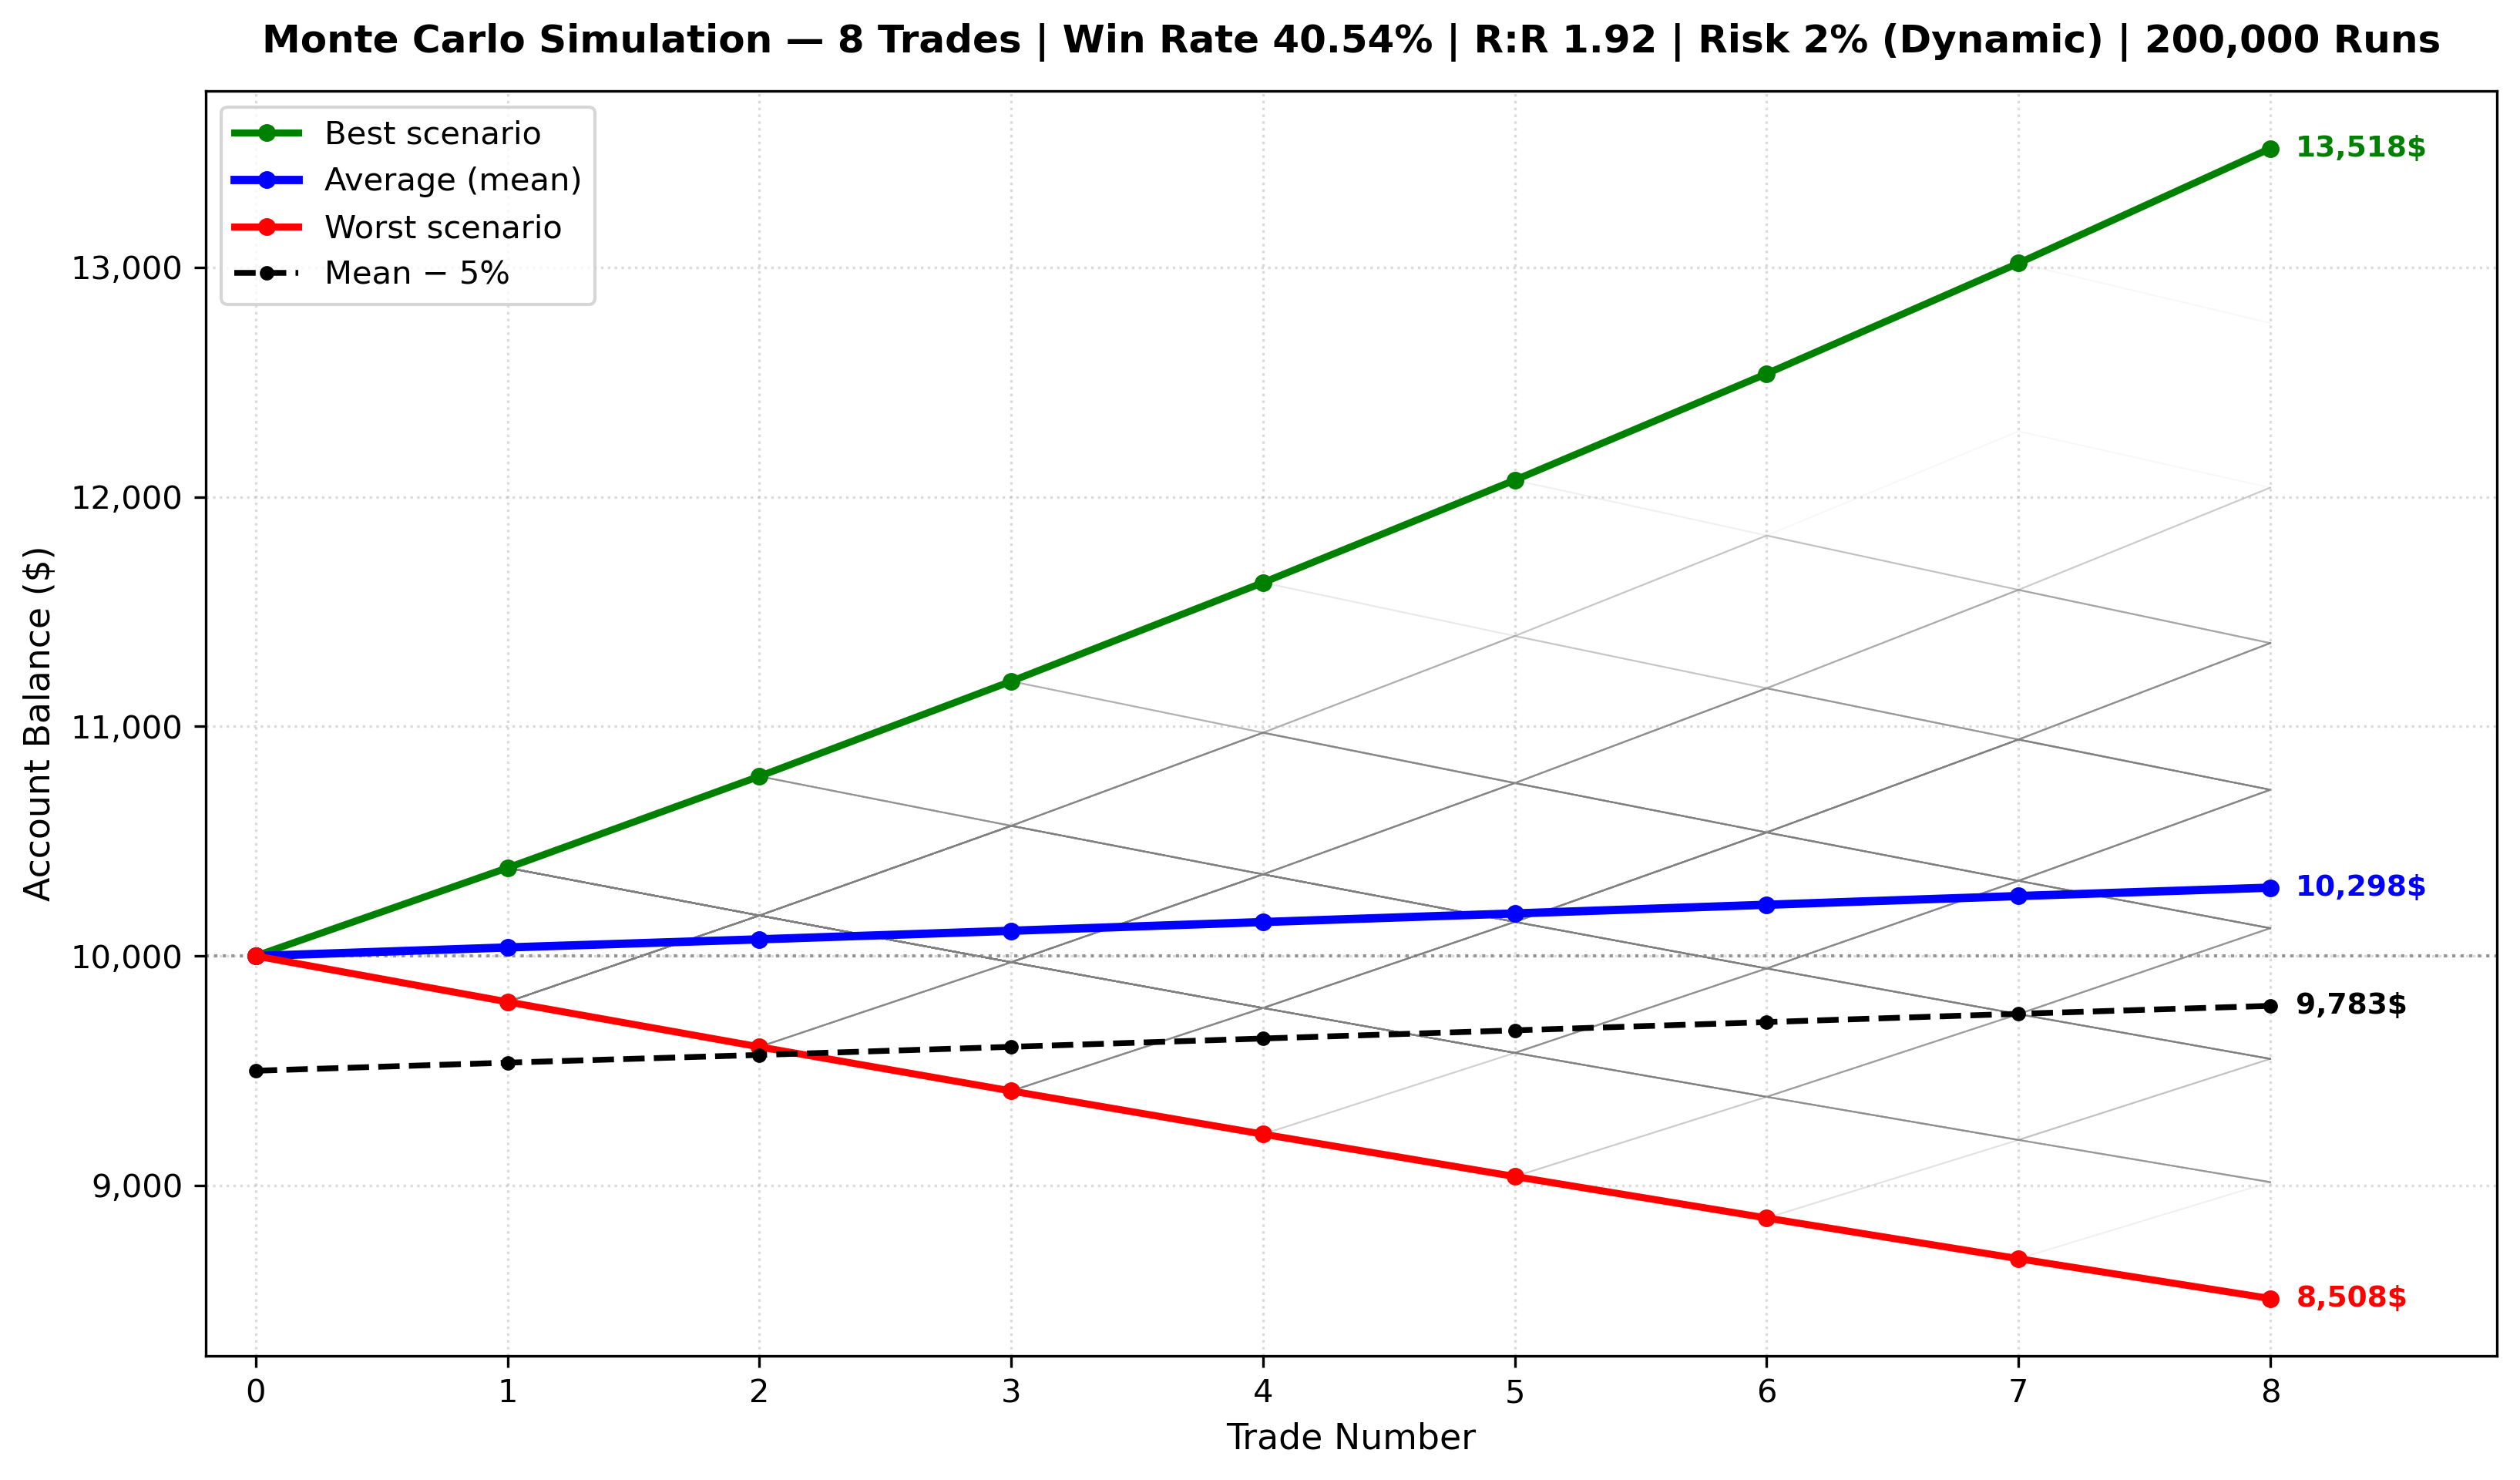


نمودار ذخیره شد: monte_carlo_8_trades.jpg


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ------------------ پارامترها ------------------
N_SIMS   = 200_000          # تعداد تکرار مونت‌کارلو
N_TRADES = 8                # تعداد معاملات هر سناریو
INITIAL  = 10_000.0         # سرمایه اولیه (دلار)
WIN_RATE = 0.4054           # وین‌ریت 40.54%
RR       = 1.92             # ریوارد به ریسک
RISK     = 0.02             # ریسک 2% پویا از مانده فعلی

rng = np.random.default_rng(42)

# ------------------ شبیه‌سازی مونت‌کارلو ------------------
# برای هر تکرار و هر معامله: True = برد، False = باخت
wins = rng.random((N_SIMS, N_TRADES)) < WIN_RATE

# ماتریس مانده حساب: ستون 0 = سرمایه اولیه، ستون‌های 1..8 = بعد از هر معامله
equity = np.empty((N_SIMS, N_TRADES + 1), dtype=np.float64)
equity[:, 0] = INITIAL

for t in range(N_TRADES):
    risk_amt = equity[:, t] * RISK                       # 2% از مانده *همان لحظه*
    pnl      = np.where(wins[:, t], risk_amt * RR, -risk_amt)
    equity[:, t + 1] = equity[:, t] + pnl

# ------------------ آماره‌ها ------------------
x            = np.arange(N_TRADES + 1)
best         = equity.max(axis=0)
worst        = equity.min(axis=0)
mean         = equity.mean(axis=0)
mean_minus_5 = mean * 0.95          # 5% کمتر از میانگین در هر نقطه

# ------------------ چاپ خلاصه ------------------
print(f"{'Trade':>5} | {'Best':>10} | {'Mean':>10} | {'Mean-5%':>10} | {'Worst':>10}")
print("-" * 62)
for i in x:
    print(f"{i:>5} | {best[i]:>10,.0f} | {mean[i]:>10,.0f} | "
          f"{mean_minus_5[i]:>10,.0f} | {worst[i]:>10,.0f}")

final = equity[:, -1]
print("\n--- خلاصه بعد از 8 معامله ---")
print(f"احتمال سوددهی        : {(final > INITIAL).mean()*100:.2f}%")
print(f"میانه مانده نهایی    : {np.median(final):,.0f} $")
print(f"میانگین مانده نهایی  : {final.mean():,.0f} $")
print(f"بهترین سناریو        : {final.max():,.0f} $")
print(f"بدترین سناریو        : {final.min():,.0f} $")

# ------------------ نمودار ------------------
fig, ax = plt.subplots(figsize=(11, 6.5), dpi=300)

# چند مسیر تصادفی کمرنگ برای حس بصری مونت‌کارلو (اختیاری)
sample_idx = rng.choice(N_SIMS, size=300, replace=False)
for i in sample_idx:
    ax.plot(x, equity[i], color='gray', lw=0.5, alpha=0.06, zorder=1)

# خطوط اصلی
ax.plot(x, best,  color='green', lw=2.2, marker='o', ms=4.5,
        label='Best scenario', zorder=5)
ax.plot(x, mean,  color='blue',  lw=2.6, marker='o', ms=4.5,
        label='Average (mean)', zorder=5)
ax.plot(x, worst, color='red',   lw=2.2, marker='o', ms=4.5,
        label='Worst scenario', zorder=5)
ax.plot(x, mean_minus_5, color='black', lw=1.8, ls='--', marker='o', ms=3.5,
        label='Mean − 5%', zorder=5)

# برچسب مقدار انتهایی روی هر خط
for y_arr, color in [(best, 'green'), (mean, 'blue'),
                     (mean_minus_5, 'black'), (worst, 'red')]:
    ax.annotate(f"{y_arr[-1]:,.0f}$",
                xy=(x[-1], y_arr[-1]),
                xytext=(8, 0), textcoords='offset points',
                color=color, fontsize=9, fontweight='bold', va='center')

# استایل
ax.set_title(f"Monte Carlo Simulation — {N_TRADES} Trades | "
             f"Win Rate {WIN_RATE*100:.2f}% | R:R {RR} | "
             f"Risk {RISK*100:.0f}% (Dynamic) | {N_SIMS:,} Runs",
             fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Trade Number", fontsize=11)
ax.set_ylabel("Account Balance ($)", fontsize=11)
ax.set_xticks(x)
ax.set_xlim(-0.2, N_TRADES + 0.9)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.grid(True, ls=':', alpha=0.45)
ax.legend(loc='upper left', frameon=True, fontsize=10)

# خط سرمایه اولیه برای مرجع
ax.axhline(INITIAL, color='gray', ls=':', lw=1, alpha=0.8)

plt.tight_layout()

# ------------------ ذخیره با DPI 300 و فرمت JPG ------------------
out_file = "monte_carlo_8_trades.jpg"
plt.savefig(out_file, dpi=300, format='jpg', bbox_inches='tight',
            facecolor='white', pil_kwargs={"quality": 95})
plt.show()
print(f"\nنمودار ذخیره شد: {out_file}")

In [4]:
%pip install numpy==1.26.4 --force-reinstall

Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl (15.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled numpy-2.5.4
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python-headless 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
qiskit 2.6.0 requires numpy<3,>=2.0, but you have numpy 1.26.4 which is incompatible.
salib 1.5.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
scipy 1.18.1 requires numpy<2.8,>=2.0.0, but you have numpy 1.26.4 which is incompatible.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.18.1 which is incompatible.
streamlit 1.37.1 requires protobuf<6,>=3.20, but you have protobuf 6.32.1 which is incompatible.
